In [1]:
# Let's add the root directory to our system search path to allow imports from sibling directories.
import os, sys
module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

In [2]:
import gc
from pathlib import Path
from typing import List

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
from vismatch import get_matcher
from vismatch.viz import plot_matches, plot_keypoints


DIR = Path("../temp/misc/registration")

Raw matches: 45060, after ratio test: 3602
Affine inliers: 228 / 3602
Homography:
 [[  1.003   -0.0115  26.2079]
 [  0.0177   1.0011 -16.7571]
 [  0.      -0.       1.    ]]


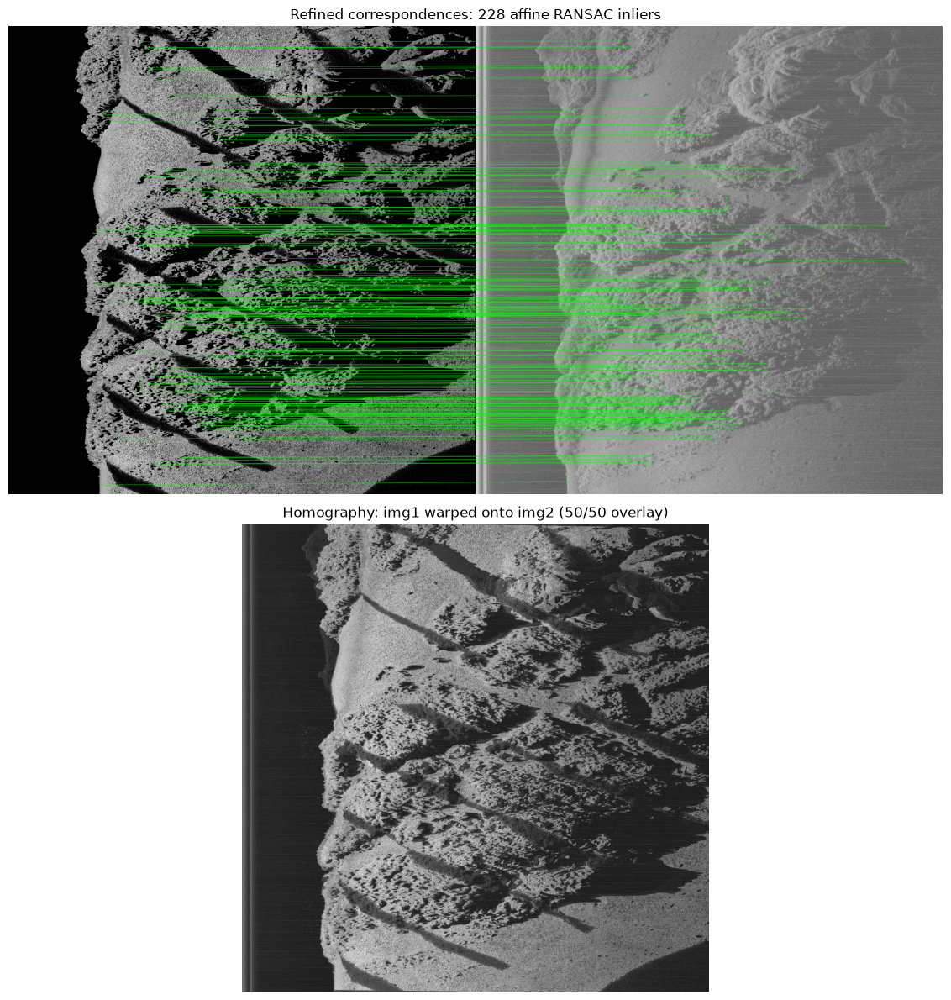

Raw matches: 25916, after ratio test: 1578
Affine inliers: 7 / 1578
Homography:
 [[  0.9977  -0.0172 -40.2413]
 [ -0.0109   0.9794   8.3782]
 [ -0.       0.       1.    ]]


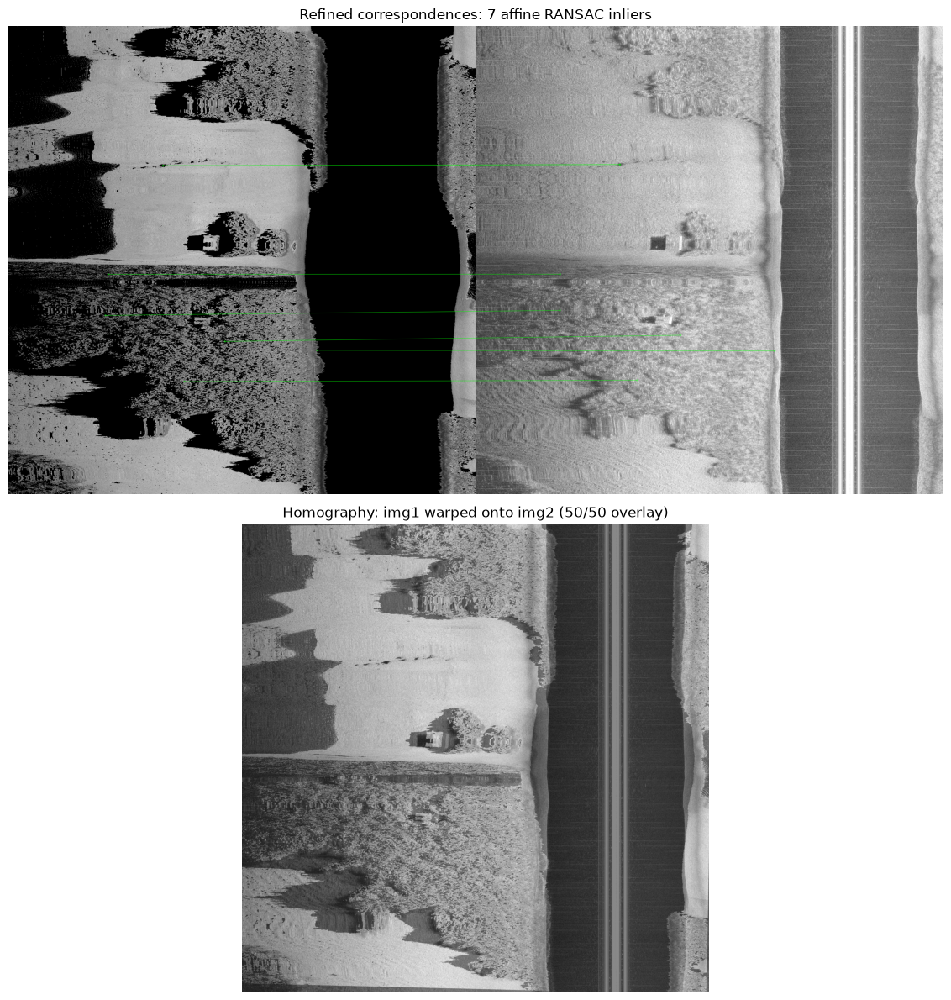

In [3]:
for i in range(1, 3):
    # ---------- 1. Load images ----------
    img1 = cv2.imread(str(DIR / f"synth{i}.png"), cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(str(DIR / f"sonar{i}.png"), cv2.IMREAD_GRAYSCALE)
    if img1 is None or img2 is None:
        raise FileNotFoundError("Could not load one of the images")

    # ---------- 2. Detect and describe features (SIFT) ----------
    sift = cv2.SIFT_create(nfeatures=1_000_000)
    kp1, des1 = sift.detectAndCompute(img1, None)
    kp2, des2 = sift.detectAndCompute(img2, None)

    # ---------- 3. Match descriptors (kNN + Lowe's ratio test) ----------
    bf = cv2.BFMatcher()
    raw_matches = bf.knnMatch(des1, des2, k=2)

    good_matches = []
    for m, n in raw_matches:
        if m.distance < 0.9 * n.distance:
            good_matches.append(m)
    print(f"Raw matches: {len(raw_matches)}, after ratio test: {len(good_matches)}")

    # ---------- 4. RANSAC refinement (affine model) ----------
    if len(good_matches) >= 3:
        src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        affine_mat, inlier_mask = cv2.estimateTranslation2D(
            src_pts, dst_pts,
            method=cv2.RANSAC,
            ransacReprojThreshold=30.0,
            maxIters=5000,
            confidence=0.995,
        )
        inlier_matches = [m for m, ok in zip(good_matches, inlier_mask.ravel()) if ok]
        print(f"Affine inliers: {len(inlier_matches)} / {len(good_matches)}")
    else:
        raise RuntimeError("Not enough matches for RANSAC")

    # ---------- 5. Homography from RANSAC inliers ----------
    src_in = np.float32([kp1[m.queryIdx].pt for m in inlier_matches]).reshape(-1, 1, 2)
    dst_in = np.float32([kp2[m.trainIdx].pt for m in inlier_matches]).reshape(-1, 1, 2)

    H, _ = cv2.findHomography(src_in, dst_in, method=0)  # least squares on inliers
    print("Homography:\n", np.array_str(H, precision=4, suppress_small=True))

    # ---------- 6. Visualize with matplotlib ----------
    # (a) Refined correspondences (inliers only)
    img_matches = cv2.drawMatches(
        img1, kp1, img2, kp2, inlier_matches, None,
        matchColor=(0, 255, 0),
        singlePointColor=(255, 0, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    # drawMatches output is BGR-ish; convert for matplotlib
    img_matches_rgb = cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB)

    # (b) Homography effect: warp img1 into img2's frame and overlay
    h, w = img2.shape
    warped = cv2.warpPerspective(img1, H, (w, h))
    overlay = cv2.addWeighted(img2, 0.5, warped, 0.5, 0)

    fig, axes = plt.subplots(2, 1, figsize=(16, 12))

    axes[0].imshow(img_matches_rgb)
    axes[0].set_title(f"Refined correspondences: {len(inlier_matches)} affine RANSAC inliers")
    axes[0].axis("off")

    axes[1].imshow(overlay, cmap="gray")
    axes[1].set_title("Homography: img1 warped onto img2 (50/50 overlay)")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [4]:
def _to_np_pts(kpts):
    """Convert keypoints (torch tensor [N,2] or numpy) to np.float32 (N,1,2)."""
    if isinstance(kpts, torch.Tensor):
        kpts = kpts.cpu().numpy()
    kpts = np.asarray(kpts, dtype=np.float32)
    if kpts.ndim == 2:
        kpts = kpts.reshape(-1, 1, 2)
    return kpts


def _to_cv_img(img):
    """Convert matcher image object to a grayscale uint8 numpy array."""
    if isinstance(img, torch.Tensor):
        arr = img.squeeze().cpu().numpy()
        if arr.ndim == 3:  # CHW
            arr = arr.transpose(1, 2, 0)
    else:
        arr = np.asarray(img)
    if arr.max() <= 1.0 + 1e-6:
        arr = (np.clip(arr, 0, 1) * 255)
    return arr.astype(np.uint8)


def plot_registration_results(img0, img1, result, algo=""):
    # ---------- 1. Convert everything to numpy ----------
    imgA = _to_cv_img(img0)
    imgB = _to_cv_img(img1)

    inlier_kpts0 = _to_np_pts(result["inlier_kpts0"])
    inlier_kpts1 = _to_np_pts(result["inlier_kpts1"])
    matched_kpts0 = _to_np_pts(result["matched_kpts0"])
    matched_kpts1 = _to_np_pts(result["matched_kpts1"])
    H = result["H"]
    if isinstance(H, torch.Tensor):
        H = H.cpu().numpy()
    H = np.asarray(H, dtype=np.float64)

    print(f"[{algo}] matched: {len(matched_kpts0)}, inliers: {len(inlier_kpts0)}")

    # ---------- 2. Panel (a): draw correspondences (all matches thin, inliers thick) ----------
    hA, wA = imgA.shape[:2]
    hB, wB = imgB.shape[:2]
    h_max, w_max = max(hA, hB), wA + wB

    canvas = np.zeros((h_max, w_max), dtype=np.uint8)
    if imgA.ndim == 3:
        canvas = np.zeros((h_max, w_max, 3), dtype=np.uint8)
    canvas[:hA, :wA] = imgA
    canvas[:hB, wA:] = imgB

    # grayscale -> RGB canvas for colored lines
    if canvas.ndim == 2:
        canvas = cv2.cvtColor(canvas, cv2.COLOR_GRAY2BGR)

    # draw all matches faintly
    for p0, p1 in zip(matched_kpts0[:, 0], matched_kpts1[:, 0]):
        pt0 = tuple(np.round(p0).astype(int))
        pt1 = tuple(np.round(p1 + [wA, 0]).astype(int))
        cv2.line(canvas, pt0, pt1, (128, 128, 128), 1)

    # draw inliers in green
    for p0, p1 in zip(inlier_kpts0[:, 0], inlier_kpts1[:, 0]):
        pt0 = tuple(np.round(p0).astype(int))
        pt1 = tuple(np.round(p1 + [wA, 0]).astype(int))
        cv2.line(canvas, pt0, pt1, (0, 255, 0), 1)
        cv2.circle(canvas, pt0, 2, (255, 0, 0), -1)
        cv2.circle(canvas, pt1, 2, (255, 0, 0), -1)

    canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)

    # ---------- 3. Panel (b): warp img0 into img1's frame, 50/50 overlay ----------
    h, w = imgB.shape[:2]
    warped = cv2.warpPerspective(imgA, H, (w, h))
    if imgB.ndim == 3:
        overlay = cv2.addWeighted(imgB, 0.5, warped, 0.5, 0)
        overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    else:
        overlay_rgb = cv2.addWeighted(imgB, 0.5, warped, 0.5, 0)

    # ---------- 4. Show ----------
    fig, axes = plt.subplots(2, 1, figsize=(16, 12))

    axes[0].imshow(canvas_rgb)
    axes[0].set_title(
        f"{algo}: correspondences — {len(inlier_kpts0)} inliers "
        f"(green) / {len(matched_kpts0)} matches (gray)"
    )
    axes[0].axis("off")

    axes[1].imshow(overlay_rgb, cmap="gray" if overlay_rgb.ndim == 2 else None)
    axes[1].set_title("Homography: synth warped onto sonar (50/50 overlay)")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()



[aliked-lightglue] matched: 781, inliers: 194


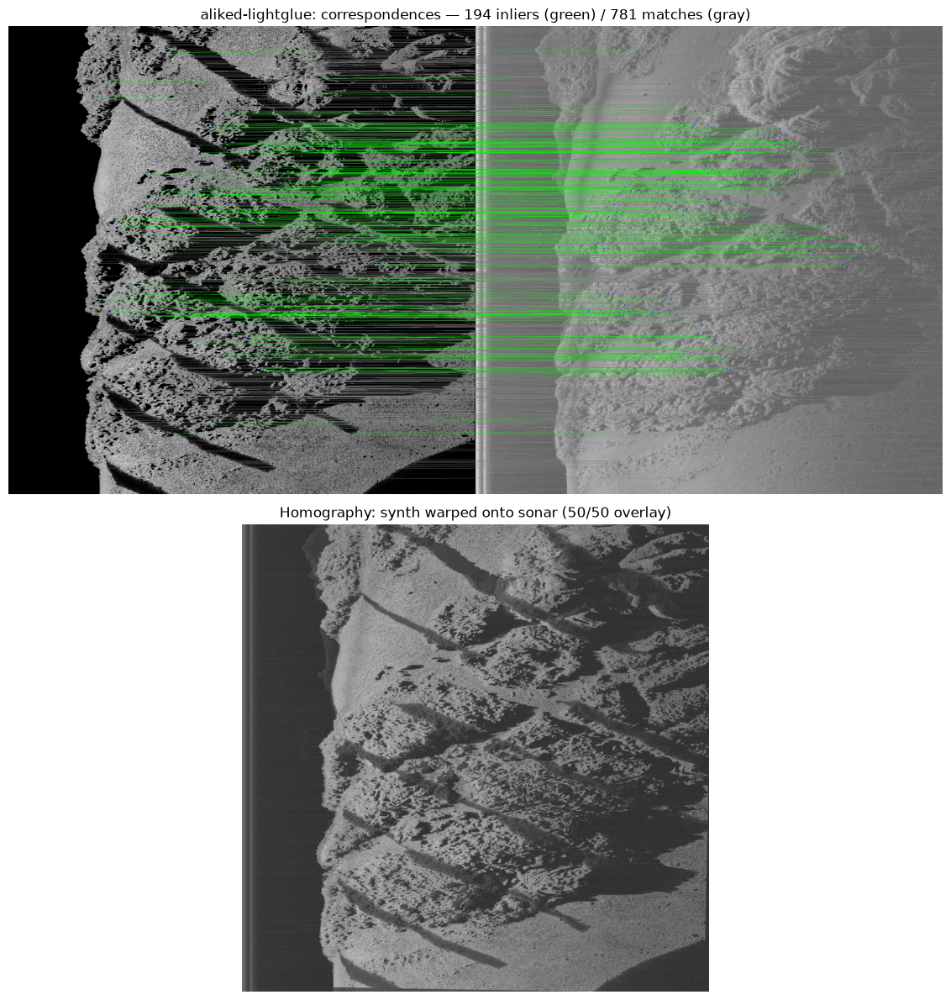

[aliked-lightglue] matched: 390, inliers: 16


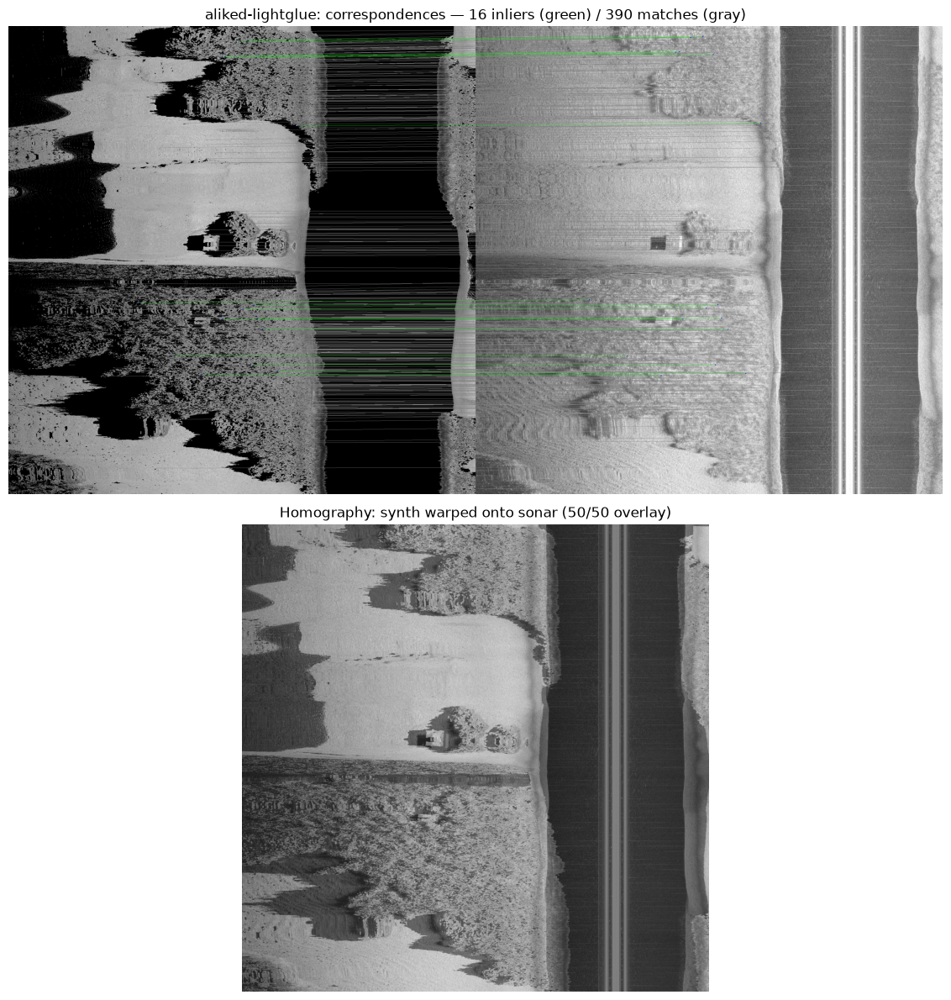

Initialize D2Net


[W1027 01:30:17.355577569 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2044723200 bytes (free: 1551171584, total: 25243287552).


[d2net] matched: 2583, inliers: 117


/tmp/ipykernel_1718900/301595777.py:95: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
[W1027 01:30:27.082745757 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2044723200 bytes (free: 1582301184, total: 25243287552).


[d2net] matched: 778, inliers: 6
[disk-lightglue] matched: 867, inliers: 200
[disk-lightglue] matched: 20, inliers: 5


/media/cirs/Filesystem2/Taqi/Masters-Thesis/venv/lib/python3.12/site-packages/vismatch/third_party/MINIMA/third_party/LightGlue/lightglue/lightglue.py:24: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


[minima-superpoint-lightglue] matched: 659, inliers: 99
[minima-superpoint-lightglue] matched: 383, inliers: 25


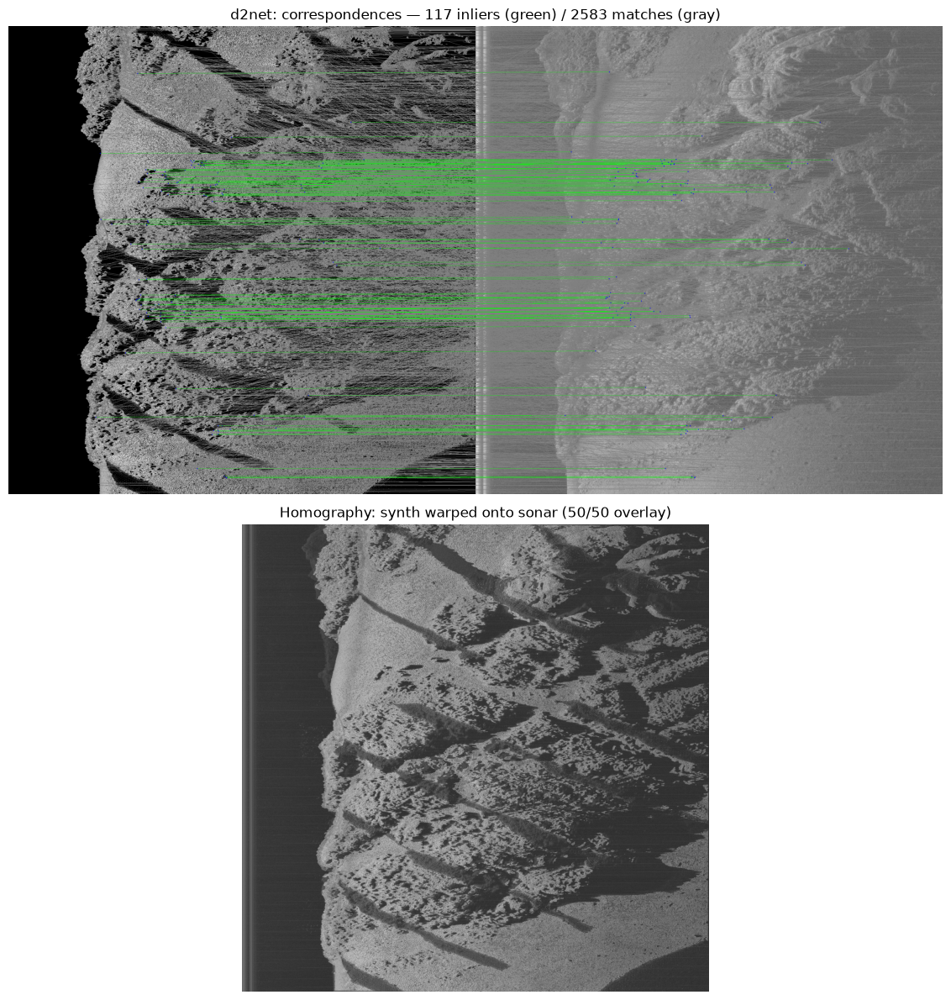

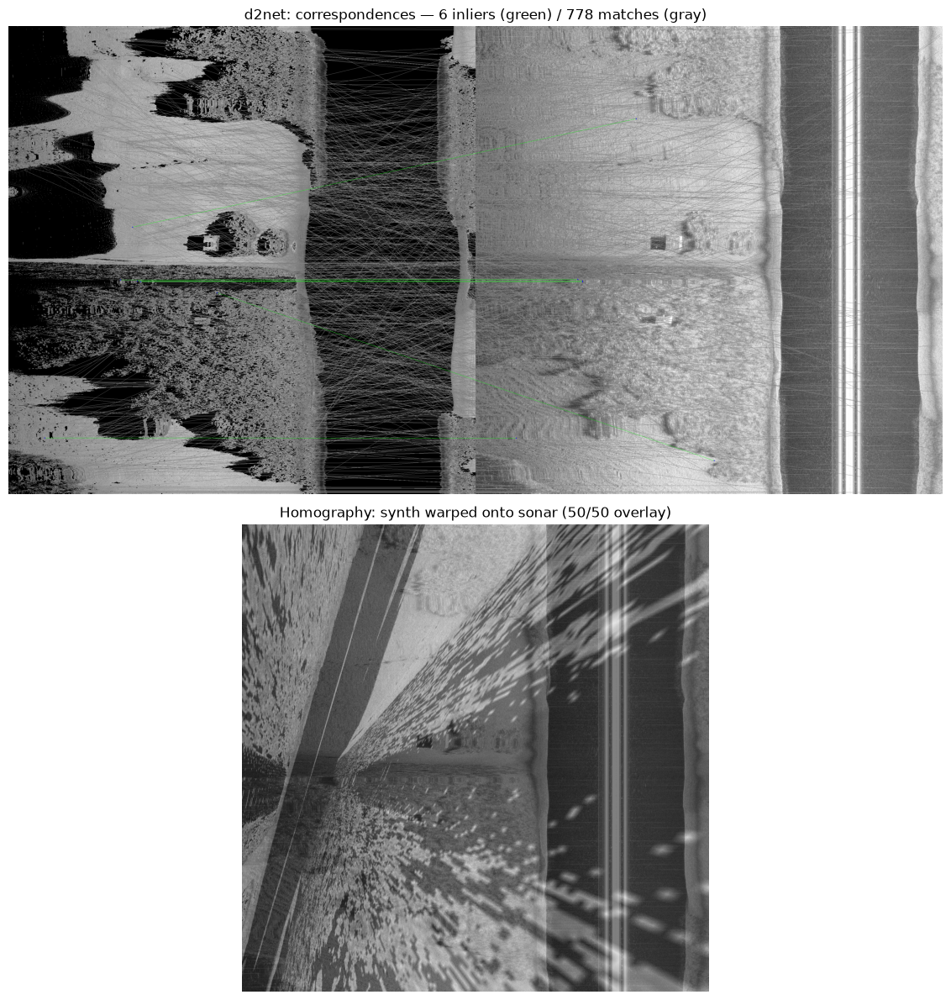

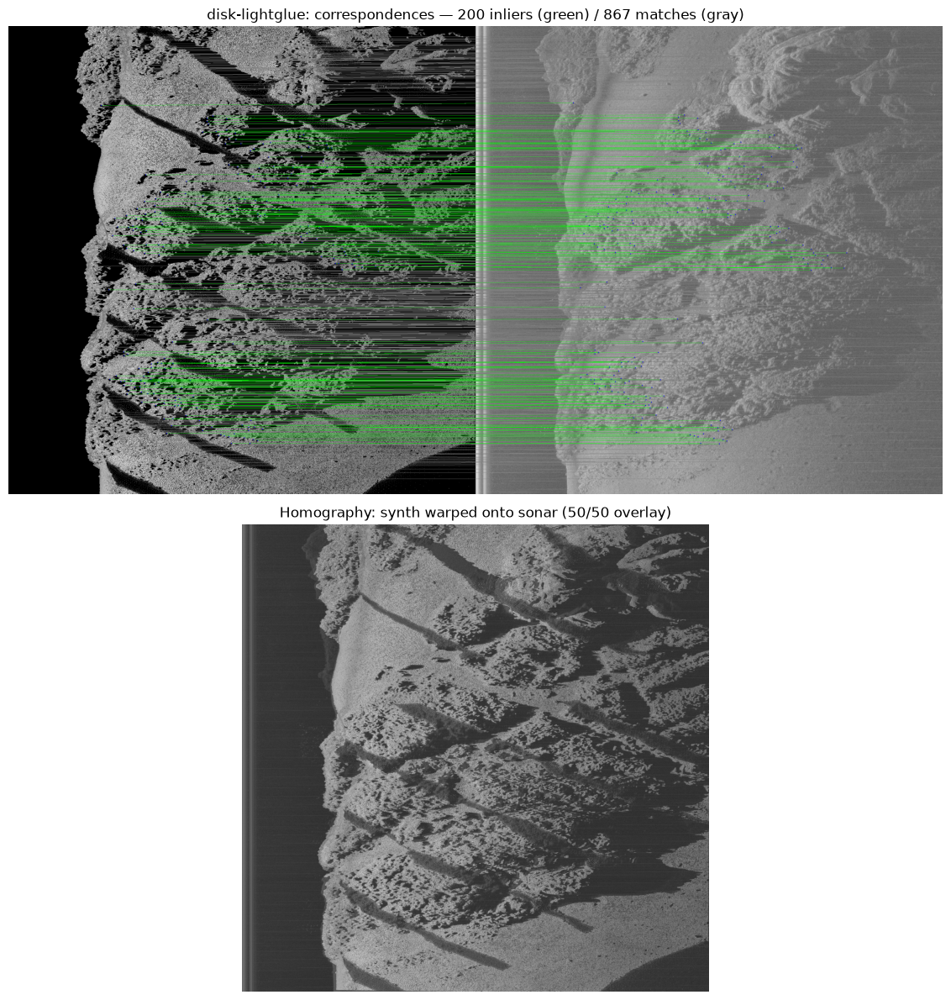

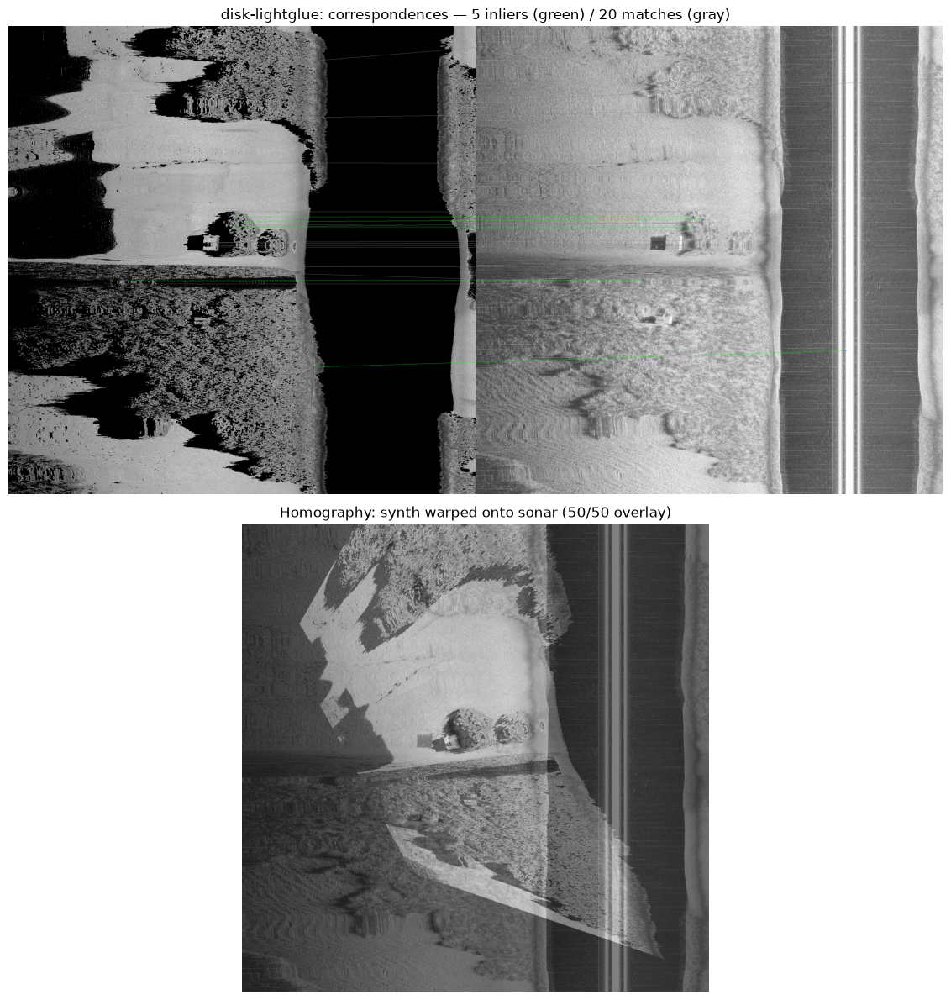

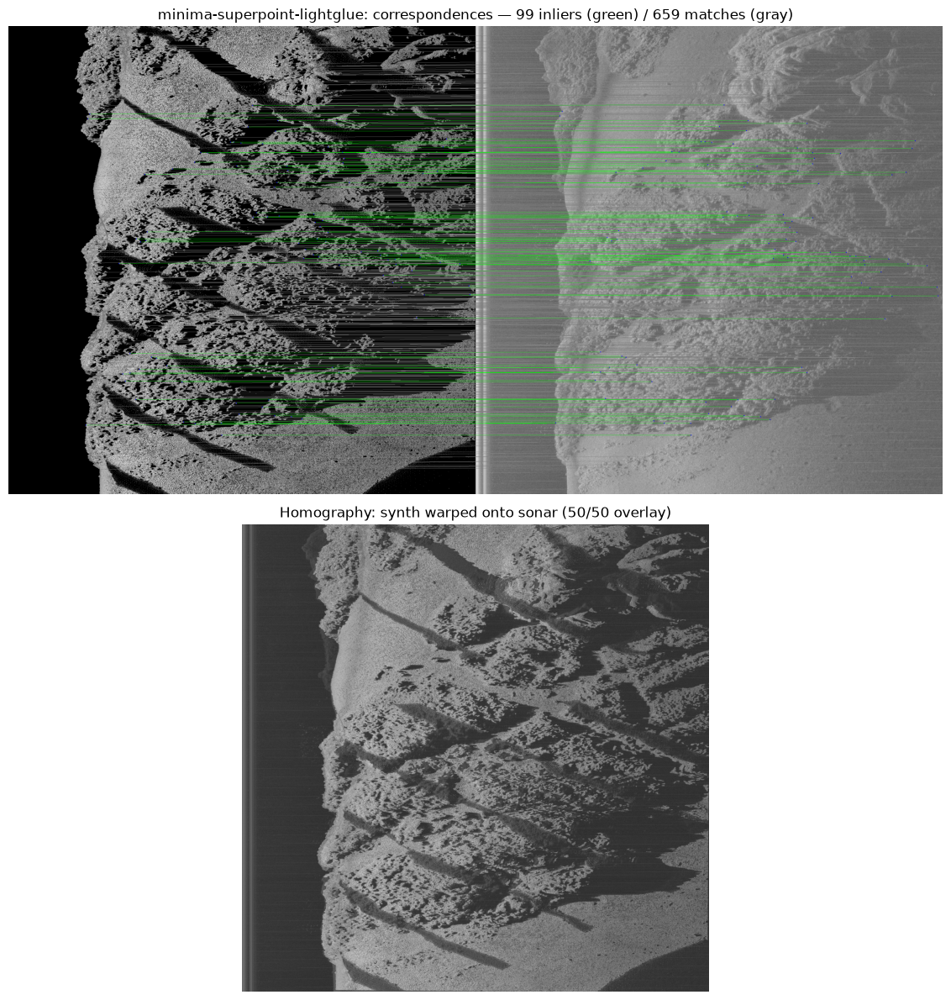

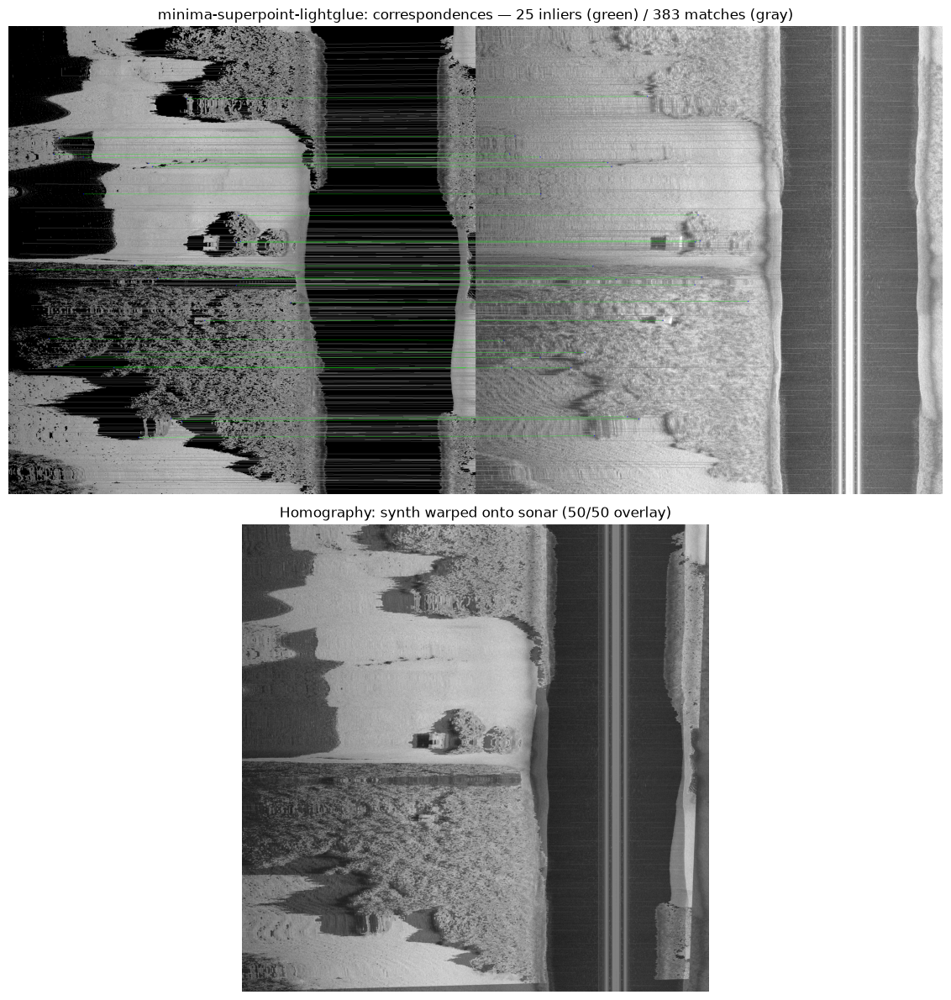

In [5]:
ALGOS = [
    # --- baselines from Chen's paper ---
    "aliked-lightglue",             # ALIKED
    "d2net",                        # D2-Net
    "disk-lightglue",               # DISK
    "minima-superpoint-lightglue",  # has Optical <-> SAR

    # "aspanformer",                # ASpanFormer
    # "loftr",                      # LoFTR
    # "eloftr",                     # E-LoFTR
    # "xoftr",                      # XoFTR
]

for algo in ALGOS:
    matcher = get_matcher(algo, device="cuda")

    for i in range(1, 3):
        img0 = matcher.load_image(str(DIR / f"synth{i}.png"))
        img1 = matcher.load_image(str(DIR / f"sonar{i}.png"))

        result = matcher(img0, img1)
        plot_registration_results(img0, img1, result, algo=algo)

        del img0, img1, result
        gc.collect()
        torch.cuda.empty_cache()

    del matcher
    gc.collect()
    torch.cuda.empty_cache()
